# CP2/CP5 — Modelagem preditiva

A identificação completa do grupo está na versão de entrega dos notebooks.

## Dados usados

Foi usada a mesma base de consumo de cerveja em São Paulo do CP1, disponível no [Kaggle](https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo?resource=download). A página foi consultada em 27/10/2026; a data do download original não ficou registrada.

Cada linha corresponde a um dia de 2015. As sete colunas trazem a data, as temperaturas média, mínima e máxima em °C, a precipitação em mm, o indicador de fim de semana (0 ou 1) e o consumo. O tema é o planejamento de estoque de bebidas no contexto dessa amostra de São Paulo.

Os cálculos mantêm os valores originais da coluna de consumo, rotulada como litros. A escala física e a procedência primária ainda precisam de confirmação antes de uso operacional. Não foram combinadas outras bases.

Não há informações sobre idade, condição de estudante, horários ou feriados. Por isso, a análise não faz conclusões sobre esses grupos ou recortes. Os resultados descrevem 2015, não a situação atual de São Paulo.

## O que queremos prever

A tarefa é estimar o consumo diário a partir das temperaturas média, mínima e máxima, da precipitação e do indicador de fim de semana. Como o resultado é numérico, trata-se de um problema de regressão supervisionada.

O alvo é a coluna `Consumo de cerveja (litros)`, na escala original do arquivo. O consumo e os indicadores calculados a partir dele não entram como preditores. A data é usada para organizar a separação dos períodos.

Essa estimativa pode ajudar no planejamento de demanda e estoque. Para prever um dia futuro, porém, seria necessário fornecer uma previsão do clima. Aqui, a avaliação usa o clima observado e não inclui o erro meteorológico.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT/'analysis.py').exists():
    raise RuntimeError('Execute o notebook a partir da pasta pacote_revisao')
sys.path.insert(0, str(ROOT))
from analysis import *
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
df, quality = load_data()
display(pd.Series(quality, name='Qualidade'))
display(df.head())

linhas_originais                                                         941
linhas_vazias_removidas                                                  576
linhas_validas                                                           365
ausentes                                                                   0
duplicadas                                                                 0
sha256_csv                 57a1df4479336ac4a6510fc7cc84f3a37eff88d0bdb915...
Name: Qualidade, dtype: object

,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
0,2015-01-01,27.30,23.9,32.5,0.0,0,25.461
1,2015-01-02,27.02,24.5,33.5,0.0,0,28.972
2,2015-01-03,24.82,22.4,29.9,0.0,1,30.814
3,2015-01-04,23.98,21.5,28.6,1.2,1,29.799
4,2015-01-05,23.82,21.0,28.3,0.0,0,28.900


## Preparação e separação dos períodos

A limpeza segue o CP1. Os dados são separados em ordem de data: 60% para treino, 20% para validação e 20% para teste. A padronização é ajustada somente nos dados usados em cada treinamento.

As configurações dos modelos estão no código e não foram escolhidas a partir do teste. Primeiro comparamos os modelos pelo RMSE da validação. Em seguida, ajustamos cada modelo em treino e validação juntos e fazemos a avaliação final no teste.

In [2]:
display(pd.DataFrame({'feature':FEATURES})); display(pd.Series({'target':TARGET}))
n1,n2=int(len(df)*.6),int(len(df)*.8)
X_train,y_train=df.iloc[:n1][FEATURES],df.iloc[:n1][TARGET]
X_val,y_val=df.iloc[n1:n2][FEATURES],df.iloc[n1:n2][TARGET]
X_test,y_test=df.iloc[n2:][FEATURES],df.iloc[n2:][TARGET]
print('Shapes:',X_train.shape,X_val.shape,X_test.shape)
assert df.iloc[:n1].Data.max()<df.iloc[n1:n2].Data.min()<df.iloc[n2:].Data.min()

,feature
0,Temperatura Media (C)
1,Temperatura Minima (C)
2,Temperatura Maxima (C)
3,Precipitacao (mm)
4,Final de Semana


target    Consumo de cerveja (litros)
dtype: str

Shapes: (219, 5) (73, 5) (73, 5)


## Modelos comparados

1. **Ridge, do scikit-learn:** uma regressão linear com regularização, usada como referência simples.
2. **XGBoost:** combina árvores por boosting para representar relações não lineares. Foram usados 180 estimadores, profundidade 2 e taxa de aprendizado de 0,03.
3. **Rede neural profunda:** MLPRegressor com três camadas ocultas de 64, 32 e 16 neurônios, ReLU, Adam e até 2.500 iterações. O alvo também é padronizado com TransformedTargetRegressor para ajudar no ajuste.

A rede tem várias camadas ocultas e atende ao requisito de profundidade, mas a base pequena não garante vantagem sobre a regressão linear. O módulo abaixo contém a limpeza, o treinamento, as métricas e a gravação dos modelos.

In [3]:
display(Markdown('```python\n'+(ROOT/'analysis.py').read_text(encoding='utf-8')+'\n```'))

```python
"""Dados, indicadores e treinamento reproduzível dos checkpoints."""
from pathlib import Path
import hashlib
import json
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

ROOT = Path(__file__).resolve().parent
TARGET = 'Consumo de cerveja (litros)'
FEATURES = ['Temperatura Media (C)', 'Temperatura Minima (C)',
            'Temperatura Maxima (C)', 'Precipitacao (mm)', 'Final de Semana']
SOURCE = 'https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo'

def load_data(path=None):
    path = Path(path or ROOT / 'data/Consumo_cerveja.csv')
    raw = pd.read_csv(path)
    required = ['Data', *FEATURES, TARGET]
    if not set(required).issubset(raw.columns):
        raise ValueError('Colunas obrigatórias ausentes')
    df = raw.dropna(how='all').copy()
    for col in FEATURES + [TARGET]:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.', regex=False), errors='raise')
    df['Data'] = pd.to_datetime(df['Data'], errors='raise')
    if df[required].isna().any().any():
        raise ValueError('Dados parcialmente ausentes: revisar antes de analisar')
    if df['Data'].duplicated().any() or df.duplicated().any():
        raise ValueError('Datas/registros duplicados')
    if not df['Final de Semana'].isin([0, 1]).all():
        raise ValueError('Indicador de fim de semana inválido')
    if not (df['Final de Semana'].astype(int).values == (df['Data'].dt.day_of_week >= 5).astype(int).values).all():
        raise ValueError('Indicador de fim de semana não corresponde às datas')
    if (df['Precipitacao (mm)'] < 0).any() or (df[TARGET] < 0).any():
        raise ValueError('Chuva ou consumo negativo')
    if not ((df[FEATURES[1]] <= df[FEATURES[0]]) & (df[FEATURES[0]] <= df[FEATURES[2]])).all():
        raise ValueError('Temperaturas inconsistentes')
    df['Final de Semana'] = df['Final de Semana'].astype(int)
    df = df.sort_values('Data').reset_index(drop=True)
    quality = {'linhas_originais': len(raw), 'linhas_vazias_removidas': len(raw)-len(df),
               'linhas_validas': len(df), 'ausentes': int(df[required].isna().sum().sum()),
               'duplicadas': int(df.duplicated().sum()),
               'sha256_csv': hashlib.sha256(path.read_bytes()).hexdigest()}
    return df, quality

def indicators(df):
    if df.empty:
        return {}
    weekend = df.groupby('Final de Semana')[TARGET].mean()
    rain = df.groupby(df['Precipitacao (mm)'].gt(0))[TARGET].mean()
    return {'dias': len(df), 'consumo_medio': float(df[TARGET].mean()),
            'consumo_total_periodo': float(df[TARGET].sum()),
            'media_fim_semana': float(weekend.get(1, np.nan)),
            'media_dia_util': float(weekend.get(0, np.nan)),
            'diferenca_fim_semana_pct': float((weekend.get(1, np.nan)/weekend.get(0, np.nan)-1)*100),
            'media_com_chuva': float(rain.get(True, np.nan)),
            'media_sem_chuva': float(rain.get(False, np.nan)),
            'correlacao_tmax': float(df[FEATURES[2]].corr(df[TARGET])) if len(df)>1 else np.nan}

def score(model, X, y):
    p = model.predict(X)
    return {'MAE': float(mean_absolute_error(y,p)),
            'RMSE': float(np.sqrt(mean_squared_error(y,p))), 'R2': float(r2_score(y,p))}

def train(out=None):
    out = Path(out or ROOT/'artifacts'); out.mkdir(parents=True, exist_ok=True)
    df, quality = load_data()
    # Avaliação prospectiva: passado para treino, depois validação e teste final.
    n1, n2 = int(len(df)*.6), int(len(df)*.8)
    a, b, c = df.iloc[:n1], df.iloc[n1:n2], df.iloc[n2:]
    models = {
        'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        'XGBoost': XGBRegressor(n_estimators=180, max_depth=2, learning_rate=.03,
                               subsample=.9, colsample_bytree=1., random_state=42, n_jobs=1),
        'Rede profunda': TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), MLPRegressor(
                hidden_layer_sizes=(64,32,16), activation='relu', solver='adam',
                alpha=.1, max_iter=2500, early_stopping=False, random_state=42)),
            transformer=StandardScaler())}
    rows=[]; warning_log=[]
    for name, model in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); model.fit(a[FEATURES],a[TARGET])
        warning_log.extend([{'modelo':name,'aviso':str(w.message)} for w in caught])
        rows.append({'modelo':name, 'fase':'validacao', **score(model,b[FEATURES],b[TARGET])})
    winner = min(rows,key=lambda r:r['RMSE'])['modelo']
    # Modelo é escolhido exclusivamente pela validação, antes de avaliar o teste.
    ab = df.iloc[:n2]
    predictions = pd.DataFrame({'Data':c['Data'], 'observado':c[TARGET]})
    for name, model in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); model.fit(ab[FEATURES],ab[TARGET])
        warning_log.extend([{'modelo':name,'aviso':str(w.message)} for w in caught])
        rows.append({'modelo':name,'fase':'teste',**score(model,c[FEATURES],c[TARGET])})
        predictions[name] = model.predict(c[FEATURES])
        joblib.dump(model,out/(name.replace(' ','_')+'.joblib'))
    baseline=DummyRegressor().fit(ab[FEATURES],ab[TARGET])
    rows.append({'modelo':'Baseline média','fase':'teste',**score(baseline,c[FEATURES],c[TARGET])})
    predictions['Baseline média']=baseline.predict(c[FEATURES])
    metrics=pd.DataFrame(rows); metrics.to_csv(out/'metrics.csv', index=False)
    predictions.to_csv(out/'predictions_test.csv',index=False)
    split = {name:{'n':len(x),'inicio':str(x.Data.min().date()),'fim':str(x.Data.max().date())}
             for name,x in [('treino',a),('validacao',b),('teste',c)]}
    metadata={'seed':42,'winner_validation_rmse':winner,'features':FEATURES,'target':TARGET,
              'split':split,'quality':quality,'warnings':warning_log,
              'trained_until':str(ab.Data.max().date()),
              'note':'Artefatos treinados em treino+validação; teste não usado no ajuste ou escolha.'}
    (out/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
    return metrics, metadata

if __name__=='__main__':
    metrics, metadata=train(); print(metrics.to_string(index=False)); print(json.dumps(metadata,ensure_ascii=False,indent=2))

```

In [4]:
metrics,metadata=train()
display(metrics)
display(metadata)
assert not metadata['warnings'], metadata['warnings']

,modelo,fase,MAE,RMSE,R2
0,Ridge,validacao,2.024107,2.405374,0.744962
1,XGBoost,validacao,2.010163,2.439080,0.737765
2,Rede profunda,validacao,2.060505,2.479096,0.729090
3,Ridge,teste,2.214502,2.618879,0.513616
4,XGBoost,teste,2.239193,2.610434,0.516748
5,Rede profunda,teste,2.209101,2.657089,0.499320
6,Baseline média,teste,3.448739,4.101331,-0.192883


{'seed': 42,
 'winner_validation_rmse': 'Ridge',
 'features': ['Temperatura Media (C)',
  'Temperatura Minima (C)',
  'Temperatura Maxima (C)',
  'Precipitacao (mm)',
  'Final de Semana'],
 'target': 'Consumo de cerveja (litros)',
 'split': {'treino': {'n': 219, 'inicio': '2015-01-01', 'fim': '2015-08-07'},
  'validacao': {'n': 73, 'inicio': '2015-08-08', 'fim': '2015-10-19'},
  'teste': {'n': 73, 'inicio': '2015-10-20', 'fim': '2015-12-31'}},
 'quality': {'linhas_originais': 941,
  'linhas_vazias_removidas': 576,
  'linhas_validas': 365,
  'ausentes': 0,
  'duplicadas': 0,
  'sha256_csv': '57a1df4479336ac4a6510fc7cc84f3a37eff88d0bdb915b2f122170401ab3a82'},
 'warnings': [],
 'trained_until': '2015-10-19',
 'note': 'Artefatos treinados em treino+validação; teste não usado no ajuste ou escolha.'}

## Como avaliar a comparação

O MAE mostra o erro absoluto médio. O RMSE dá mais peso aos erros grandes. Nos dois casos, valores menores são melhores e ficam na mesma escala do consumo. O R² compara o desempenho com a média do alvo do período avaliado; ele também pode ser negativo.

A baseline prevê a média do período usado no ajuste. O modelo padrão é escolhido pelo RMSE da validação. Um resultado melhor de outro modelo no teste não muda essa escolha.

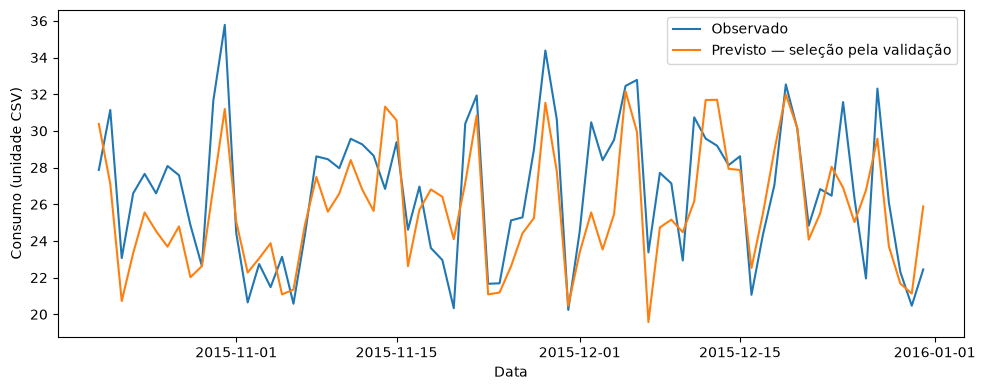

Modelo selecionado: **Ridge**. RMSE no teste: **2.619**, baseline **4.101**; MAE **2.215**, R² **0.514**.

In [5]:
pred=pd.read_csv(ROOT/'artifacts/predictions_test.csv')
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(pd.to_datetime(pred.Data),pred.observado,label='Observado')
ax.plot(pd.to_datetime(pred.Data),pred[metadata['winner_validation_rmse']],label='Previsto — seleção pela validação')
ax.set(ylabel='Consumo (unidade CSV)',xlabel='Data'); ax.legend(); plt.tight_layout(); plt.show()
selected=metrics[(metrics.modelo==metadata['winner_validation_rmse']) & (metrics.fase=='teste')].iloc[0]
base=metrics[(metrics.modelo=='Baseline média')].iloc[0]
display(Markdown(f"Modelo selecionado: **{selected['modelo']}**. RMSE no teste: **{selected.RMSE:.3f}**, baseline **{base.RMSE:.3f}**; MAE **{selected.MAE:.3f}**, R² **{selected.R2:.3f}**."))

## Relação com os indicadores e limites

No CP1, as médias e correlações descrevem as relações separadamente. Aqui, os modelos combinam os fatores para estimar o consumo de um dia. As métricas mostram quanto essas estimativas erraram fora do treinamento; elas não são um intervalo de previsão.

O teste cobre os últimos 73 dias de um único ano. Isso não demonstra desempenho em outros anos ou estabelecimentos. Além disso, as temperaturas são relacionadas entre si, o que pode tornar os coeficientes da regressão menos estáveis.

Antes de usar os resultados para decisões reais, seria necessário ampliar a série e fazer uma avaliação prospectiva. A dashboard usa os modelos já gravados, sem retreiná-los a cada consulta.